# 03 · Calibración, abstención, robustez, ONNX, Grad-CAM y API

Todo lo que se ajusta (temperaturas, peso del ensamble y umbral τ) se elige en **validación**; aquí se muestran sus efectos en **prueba**. Los costos (18, 35 y 140 USD) son **supuestos** y se analiza su sensibilidad. El velo atmosférico es **simulado**.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import json
from pathlib import Path
import os
if not Path('reports').is_dir():  # Jupyter abre el cuaderno en notebooks/: se trabaja desde la raíz
    os.chdir('..')
import pandas as pd
from IPython.display import display, Image

res = json.loads(Path('reports/resultados.json').read_text(encoding='utf-8'))
display(pd.read_csv('reports/calibracion_temperatura.csv'))
print('Peso del ensamble (elegido en validación):', res['ensamble'])

,modelo,nombre,temperatura_validacion,ece_antes,ece_despues,log_loss_antes,log_loss_despues,brier_antes,brier_despues
0,m1,1 · Espectral: 54 índices + textura + GBDT,1.2158,0.0273,0.0116,0.2780,0.2703,0.1409,0.1389
1,m2,2 · MobileNetV3 congelada + sonda lineal,1.9120,0.0528,0.0077,0.3807,0.2883,0.1517,0.1421
2,m3,3 · Fusión: embeddings CNN + 54 índices + MLP,1.9993,0.0347,0.0062,0.2330,0.1689,0.0890,0.0822
3,m4,4 · Fine-tuning parcial MobileNetV3 (D4 + TTA),0.7196,0.0440,0.0061,0.1399,0.1072,0.0552,0.0524
4,m5,5 · Ensamble M3 + M4 (calibrado con temperatura),0.8507,0.0445,0.0059,0.1251,0.0966,0.0507,0.0474


Peso del ensamble (elegido en validación): {'peso_finetuning': 0.75, 'peso_fusion': 0.25}


## Umbral de abstención: elegido en validación, evaluado en prueba

In [2]:
a = res['abstencion']
print('tau elegido en validación (M5):', a['tau_validacion_m5'], '| tau que minimizaría la prueba:', a['tau_que_minimizaria_prueba_m5'])
display(pd.DataFrame([a['validacion_m5'], a['prueba_m5']], index=['validación', 'prueba']))
display(pd.read_csv('reports/comparacion_abstencion.csv'))

tau elegido en validación (M5): 0.85 | tau que minimizaría la prueba: 0.8


,umbral_confianza,cobertura_automatica_pct,derivadas_fotointeprete_pct,exactitud_en_automaticas_pct,errores_misma_macro_restantes,errores_criticos_restantes,costo_total_por_1000_usd
validación,0.85,92.11,7.89,98.83,23,35,2476.48
prueba,0.85,92.22,7.78,99.14,9,34,2339.81


,umbral_confianza,cobertura_automatica_pct,derivadas_fotointeprete_pct,exactitud_en_automaticas_pct,errores_misma_macro_restantes,errores_criticos_restantes,costo_total_por_1000_usd,politica,modelo,costo_ic95_inf,costo_ic95_sup
0,0.00,100.00,0.00,90.30,150,374,10668.52,m1_sin_abstencion,m1,9696.13,11621.30
1,0.85,78.96,21.04,97.23,39,79,6087.59,m1_con_abstencion,m1,5609.26,6556.49
2,0.00,100.00,0.00,96.98,45,118,3350.93,m5_sin_abstencion,m5,2812.80,3914.81
3,0.85,92.22,7.78,99.14,9,34,2339.81,m5_con_abstencion,m5,2007.14,2675.62


## Sensibilidad a los costos supuestos (τ re-elegido en validación en cada escenario)

In [3]:
sens = pd.read_csv('reports/sensibilidad_costos.csv')
display(sens[sens['un_solo_cambio']])

,costo_revision,costo_misma_macro,costo_inter_macro,un_solo_cambio,tau_validacion,cobertura_automatica_pct,costo_m1_sin_abstencion,costo_m5_sin_abstencion,costo_m5_con_abstencion,ahorro_abstencion_vs_m5_pct,ahorro_m5_abst_vs_m1_pct
4,9.0,35.0,140.0,True,0.90,89.98,10668.52,3350.93,1627.59,51.4,84.7
10,18.0,17.5,140.0,True,0.85,92.22,10182.41,3205.09,2310.65,27.9,77.3
12,18.0,35.0,70.0,True,0.80,94.17,5820.37,1821.30,1685.19,7.5,71.0
13,18.0,35.0,140.0,True,0.85,92.22,10668.52,3350.93,2339.81,30.2,78.1
14,18.0,35.0,280.0,True,0.90,89.98,20364.81,6410.19,3203.33,50.0,84.3
16,18.0,70.0,140.0,True,0.85,92.22,11640.74,3642.59,2398.15,34.2,79.4
22,36.0,35.0,140.0,True,0.75,95.37,10668.52,3350.93,3176.85,5.2,70.2


## Robustez: velo simulado, ruido gaussiano y desenfoque (5 modelos)

In [4]:
display(pd.read_csv('reports/robustez_perturbaciones.csv'))

,perturbacion,nivel,acc_m1,acc_m2,acc_m3,acc_m4,acc_m5
0,velo_simulado,0.0,0.9030,0.9067,0.9433,0.9652,0.9698
1,velo_simulado,0.1,0.7752,0.7967,0.8643,0.9028,0.9046
2,velo_simulado,0.2,0.5761,0.6456,0.7026,0.7569,0.7609
3,velo_simulado,0.3,0.3904,0.4869,0.5572,0.6078,0.6178
4,velo_simulado,0.4,0.2657,0.3713,0.4280,0.4841,0.4924
5,ruido_gaussiano,0.0,0.9030,0.9067,0.9433,0.9652,0.9698
6,ruido_gaussiano,5.0,0.5246,0.7139,0.7446,0.7617,0.7657
7,ruido_gaussiano,10.0,0.2448,0.5793,0.5793,0.5519,0.5698
8,ruido_gaussiano,20.0,0.1252,0.3876,0.2704,0.2944,0.3074
9,ruido_gaussiano,30.0,0.1119,0.2980,0.1800,0.2220,0.2313


## ONNX: salidas iguales a PyTorch y latencia en CPU

In [5]:
o = res['onnx']
print('Diferencia máxima de logits:', o['diferencia_max_abs_logits'], '| misma clase:', o['pct_misma_clase_predicha'], '%')
display(pd.DataFrame(o['latencias']))

Diferencia máxima de logits: 8.463859558105469e-05 | misma clase: 100.0 %


,tamano_lote,pytorch_ms_por_lote,onnx_ms_por_lote,pytorch_ms_por_imagen,onnx_ms_por_imagen,aceleracion_onnx
0,1,5.842,0.940,5.842,0.940,6.21
1,64,39.491,16.742,0.617,0.262,2.36


## API FastAPI (inferencia con ONNX Runtime)

In [6]:
from fastapi.testclient import TestClient
from api.main import app

cliente = TestClient(app)
resp = cliente.post('/clasificar_lote', json={'parcelas': [
    {'id_parcela': 'ESCENA_BOSQUE', 'archivo_muestra': '01_Forest_01.png'},
    {'id_parcela': 'ESCENA_AUTOPISTA', 'archivo_muestra': '03_Highway_01.png'},
    {'id_parcela': 'ESCENA_RIO', 'archivo_muestra': '08_River_01.png'}
]}).json()
for r in resp['resultados']:
    print(r['id_parcela'], '->', r['clase_predicha'], r['confianza'], r['decision_operativa'])

ESCENA_BOSQUE -> Forest 0.9989 CLASIFICACION_AUTOMATICA
ESCENA_AUTOPISTA -> Highway 0.9997 CLASIFICACION_AUTOMATICA
ESCENA_RIO -> River 0.9992 CLASIFICACION_AUTOMATICA


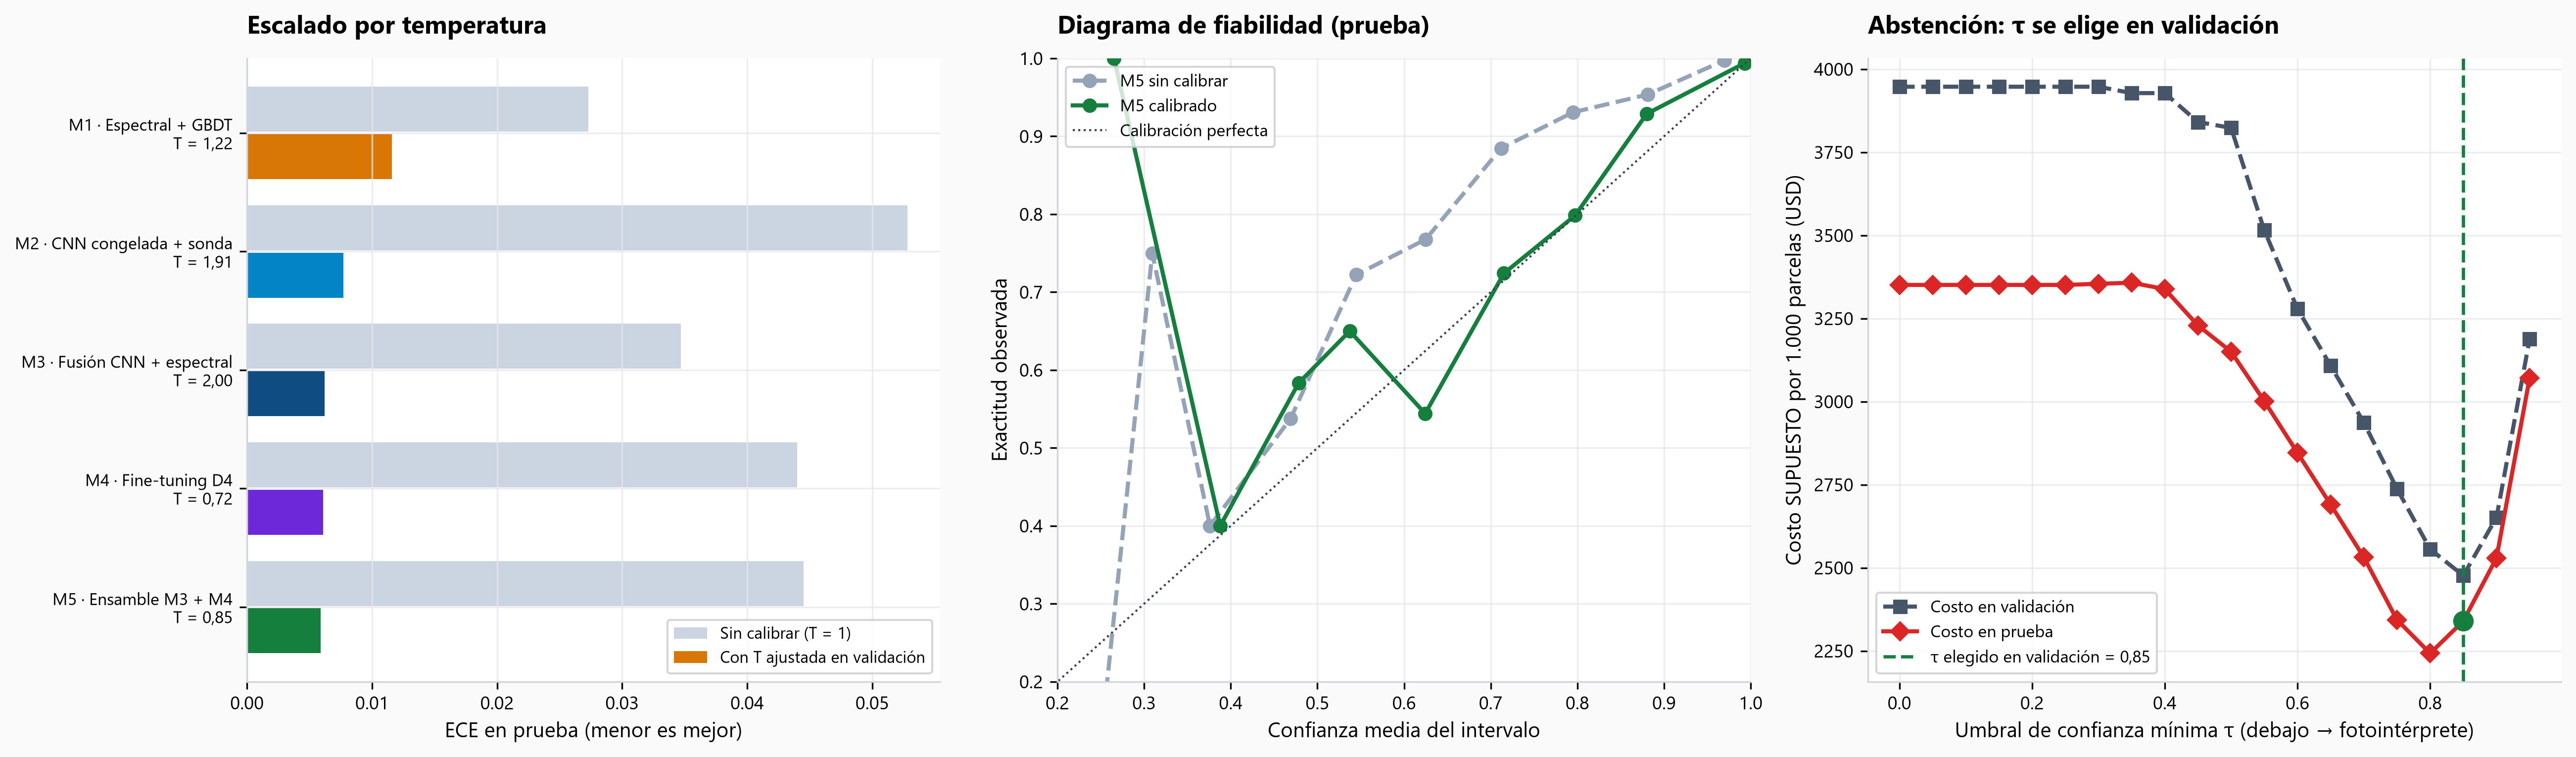

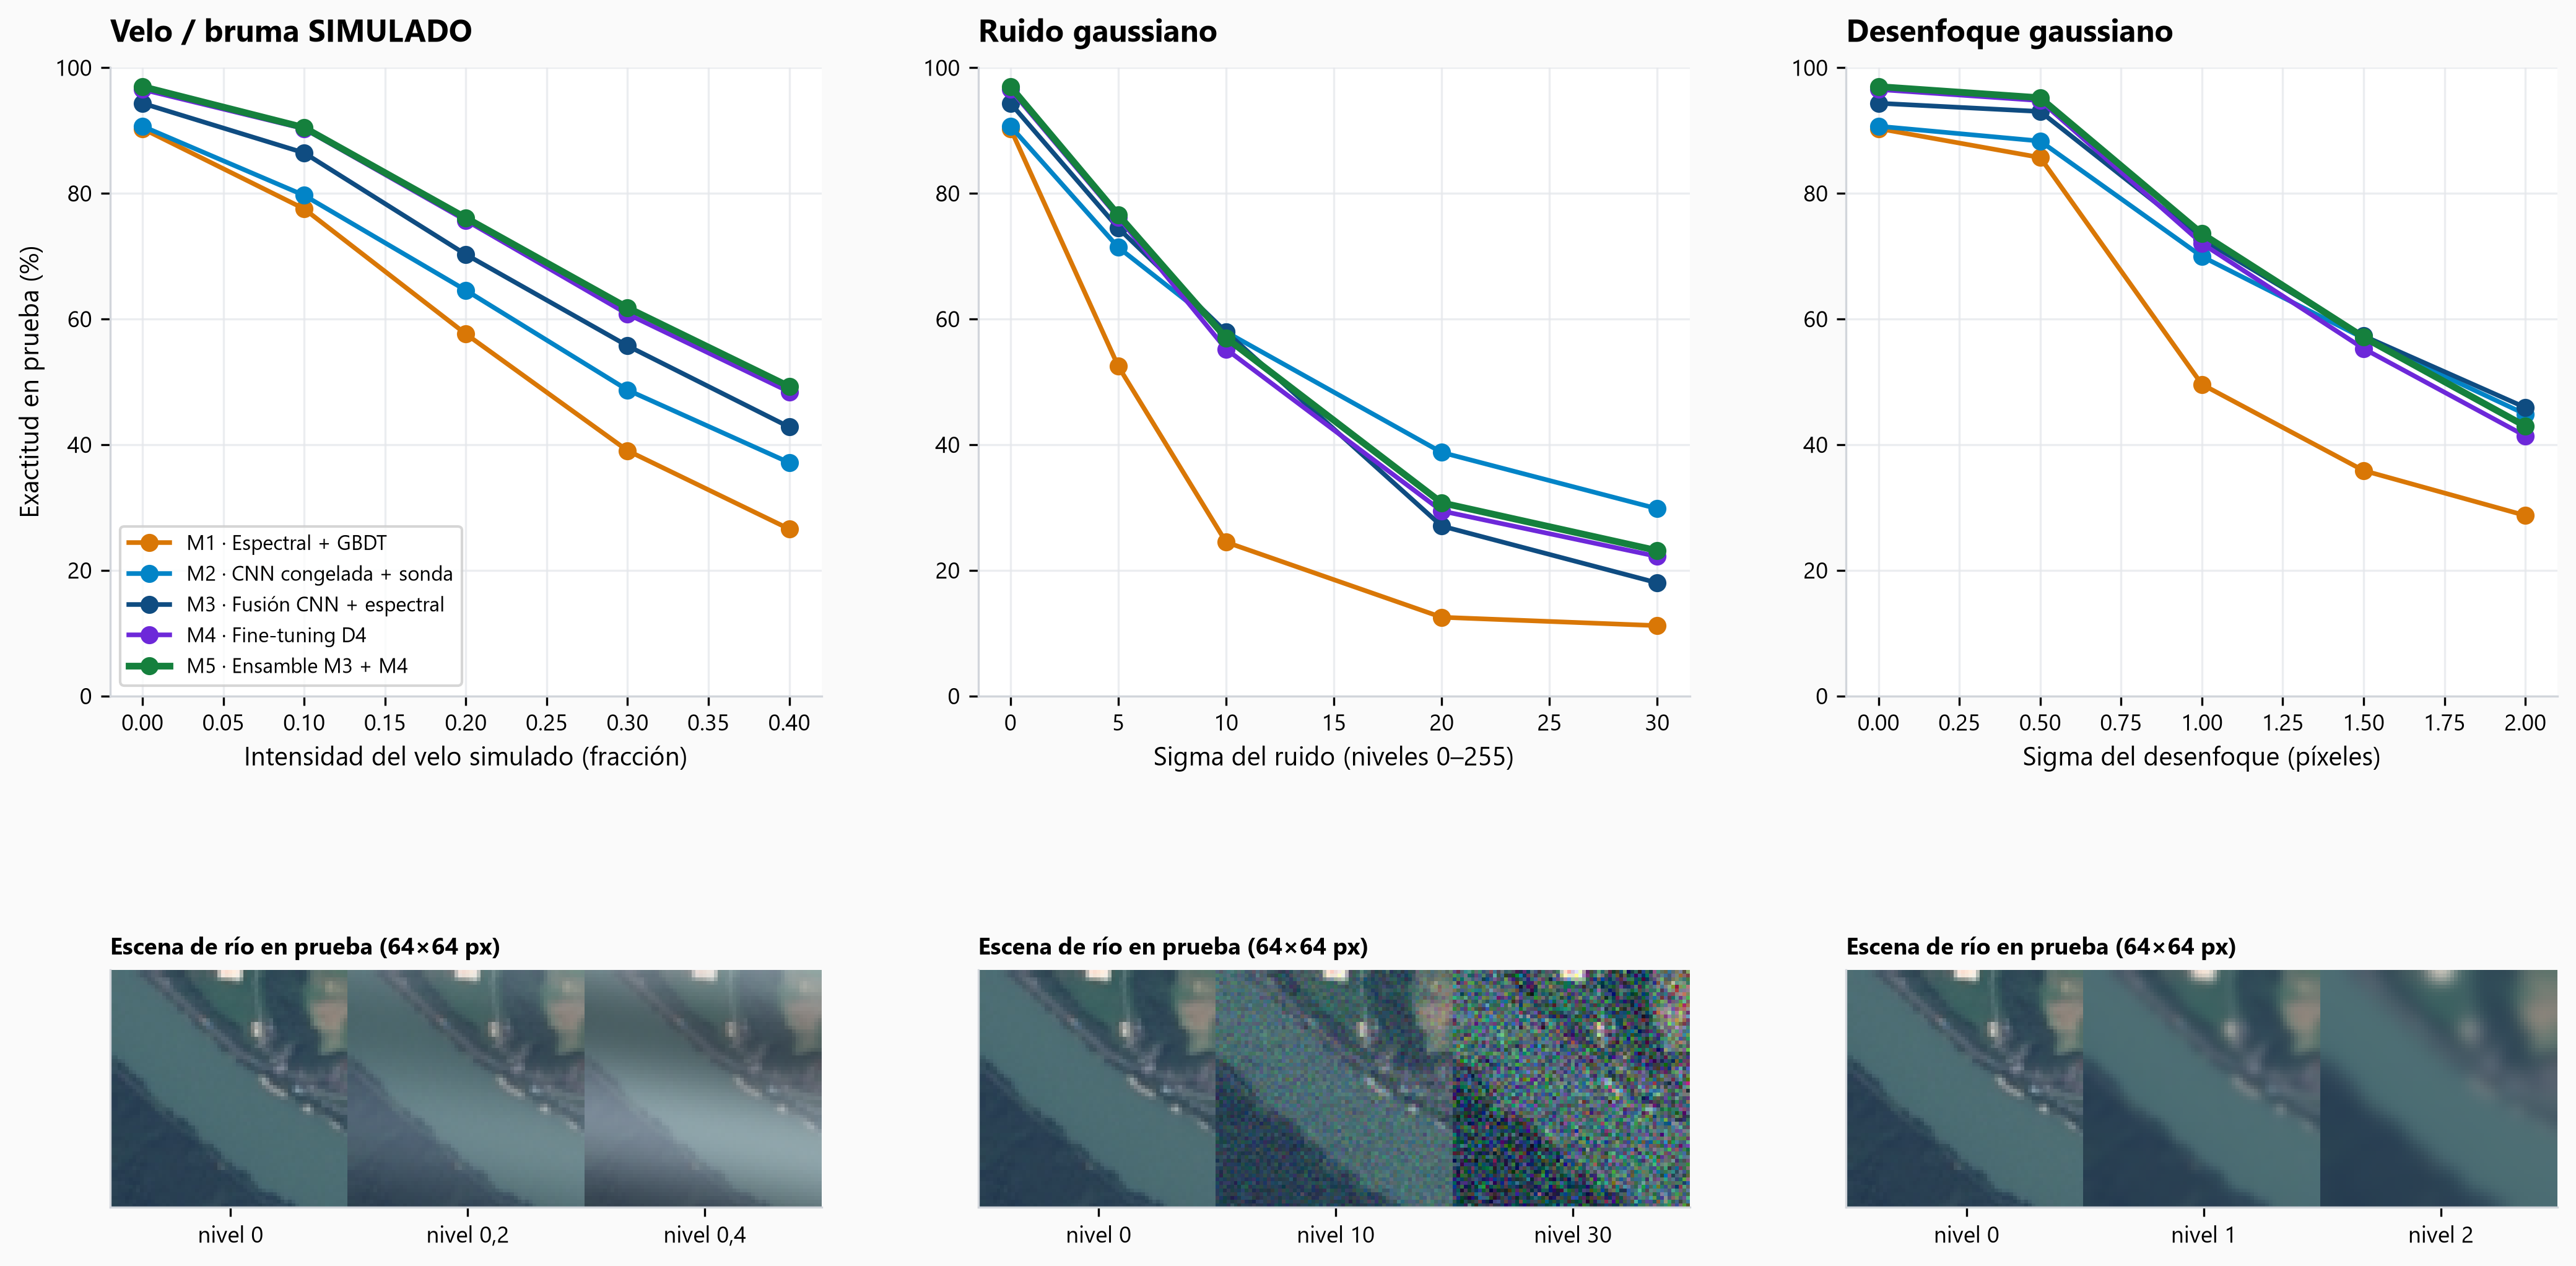

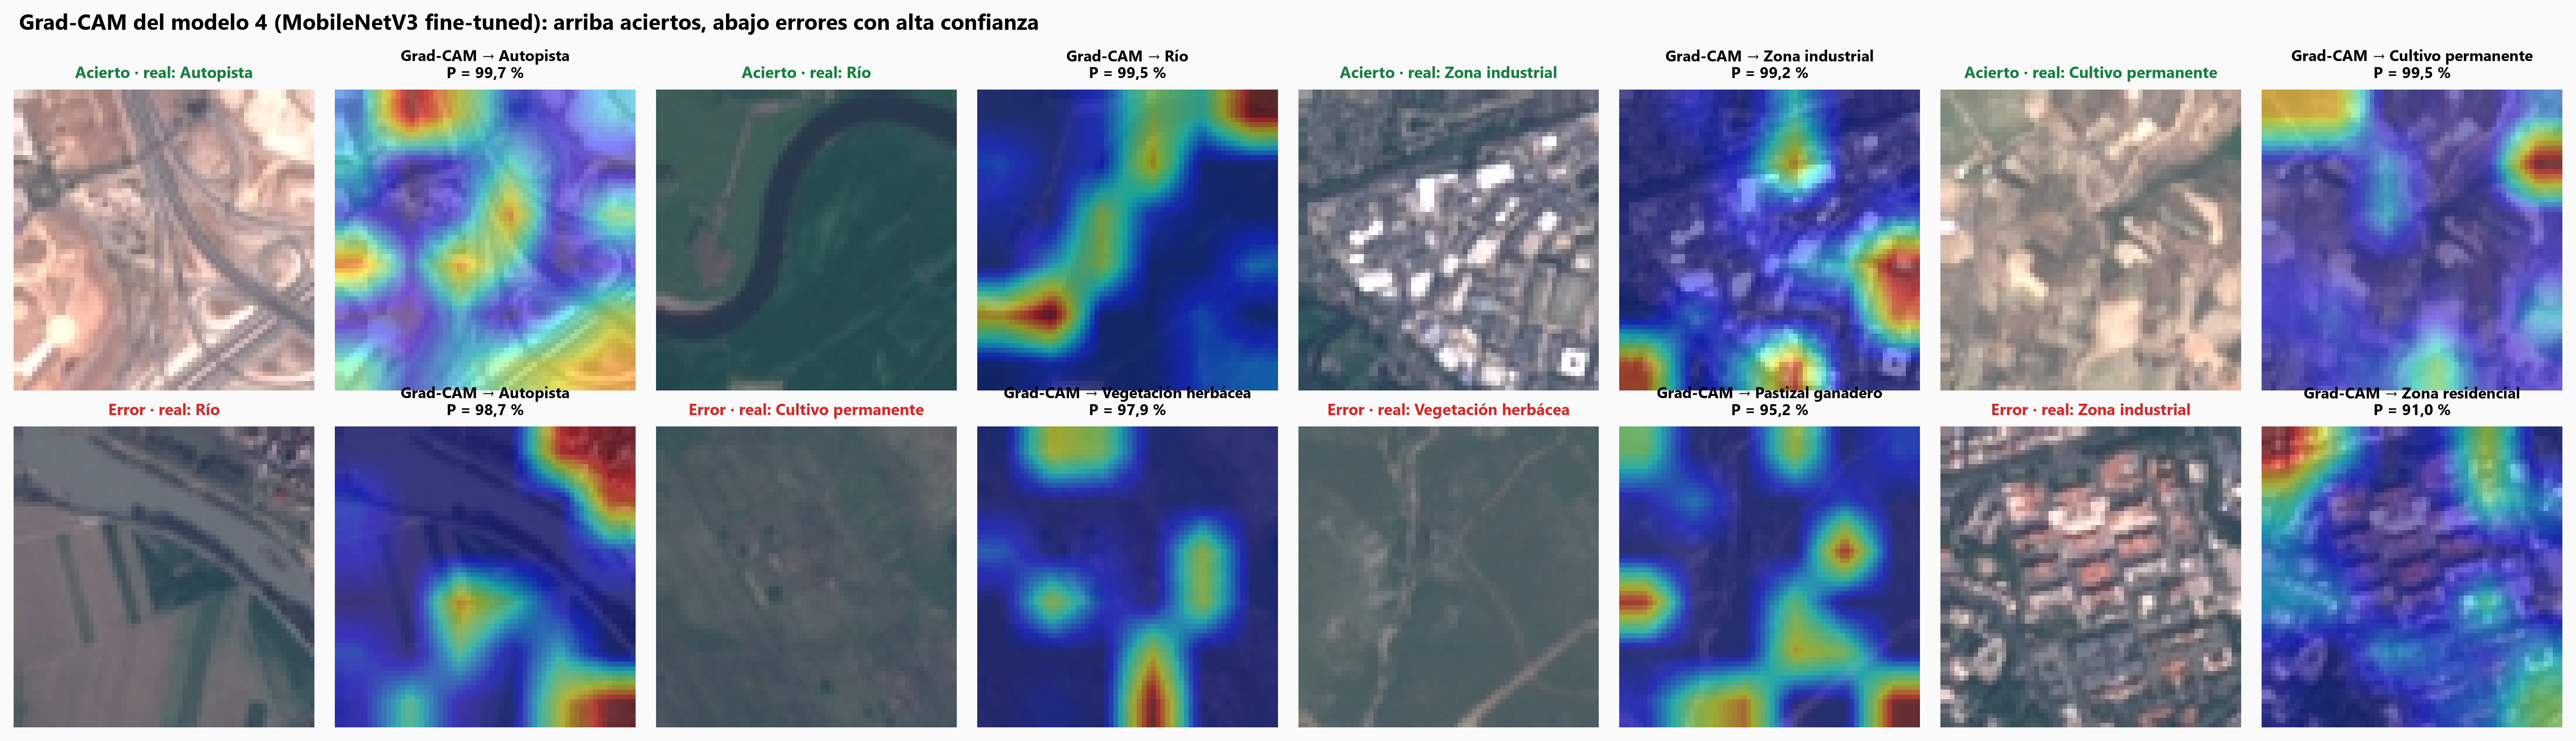

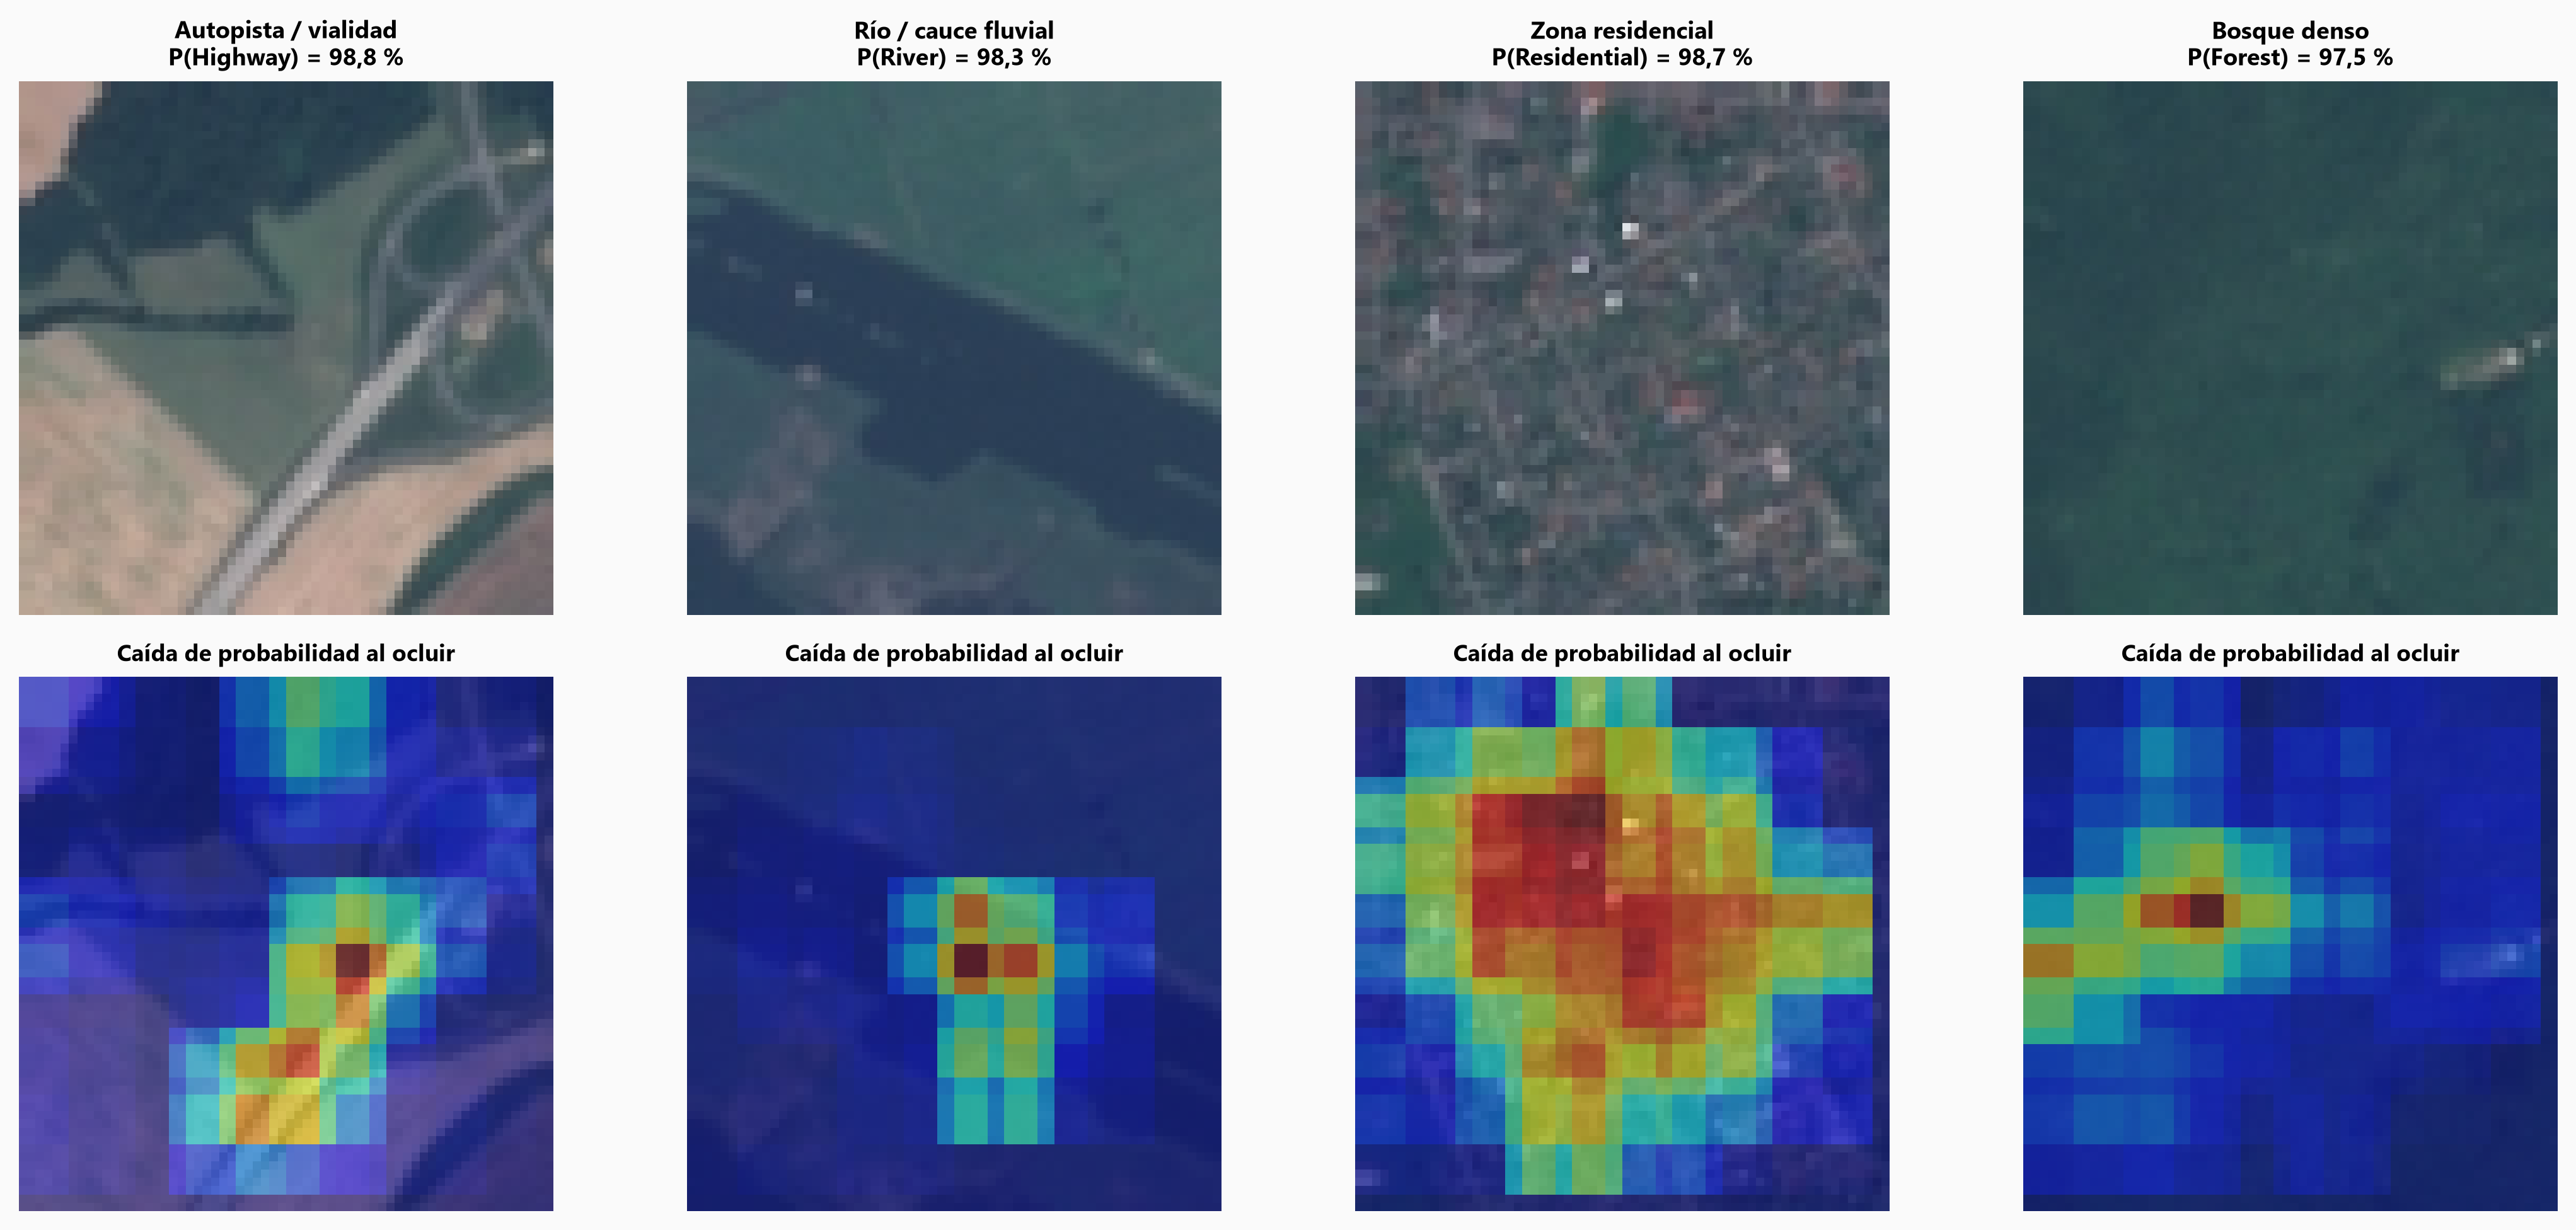

In [7]:
for f in ['06_calibracion_temperatura_y_abstencion', '07_robustez_velo_ruido_desenfoque',
          '09_grad_cam_aciertos_y_errores', '08_mapas_oclusion_espacial']:
    display(Image(f'reports/figures/{f}.png'))